# Part 3: Fine-Tuning the Part 1 SLM

This notebook continues training **Architecture / Model #3** (embedding 48, 4 heads, 1 layer, feed-forward 192, context 32) from the same `tiny_transformer.pt` checkpoint used in `assignment_P1-A7_SLM.ipynb` and `assignment_P1-A7_RAG.ipynb`. It follows the Week 6 fine-tuning procedure (`4-Fine Tuning.ipynb`): question/answer examples, loss masking with `-100`, cross-entropy, backpropagation, AdamW, a weight snapshot, a loss curve, and before/after answers. The Hugging Face model and tokenizer calls are replaced by the Week 7 SLM and its 27-character vocabulary.

The fine-tuning facts come from the same Kirkus Best-of-2025 knowledge base used for RAG. The five evaluation questions, compact cues, temperature (0.7), seed (42), and length (80 new characters) are identical to Part 2.

Part 4 (the three-condition comparison and final analysis) is at the end of this notebook.

In [1]:
# CELL 1: Load the selected Part 1 SLM from tiny_transformer.pt
# Same loader and architecture classes as assignment_P1-A7_RAG.ipynb.
from pathlib import Path
import json
import random
import time
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

SEED = 42
DEVICE = torch.device("cpu")
TEMPERATURE = 0.7
MAX_NEW_CHARACTERS = 80
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)

roots = [Path.cwd(), *Path.cwd().parents]
candidates = roots + [root / "Assignment_P1-A7" / "moveon" / "6-moveon" / "Assignment_P1-A7" for root in roots]
ASSIGNMENT_DIR = next((path for path in candidates if (path / "tiny_transformer.pt").is_file() and (path / "knowledge-base-documents").is_dir()), None)
if ASSIGNMENT_DIR is None:
    raise FileNotFoundError("Cannot locate tiny_transformer.pt beside knowledge-base-documents.")
CHECKPOINT_PATH = ASSIGNMENT_DIR / "tiny_transformer.pt"
KB_DIR = ASSIGNMENT_DIR / "knowledge-base-documents"
CORPUS_PATH = ASSIGNMENT_DIR / "training_corpus.txt"

# Match the architecture used to save the selected Part 1 checkpoint.
class TransformerBlock(nn.Module):
    def __init__(self, embedding_dim, num_heads, feedforward_dim):
        super().__init__()
        self.attention = nn.MultiheadAttention(embedding_dim, num_heads, dropout=0.0, batch_first=True)
        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)
        self.feedforward = nn.Sequential(
            nn.Linear(embedding_dim, feedforward_dim),
            nn.ReLU(),
            nn.Linear(feedforward_dim, embedding_dim)
        )

    def forward(self, x):
        length = x.shape[1]
        mask = torch.triu(torch.ones(length, length, device=x.device, dtype=torch.bool), diagonal=1)
        normalized = self.ln1(x)
        attended, _ = self.attention(normalized, normalized, normalized, attn_mask=mask, need_weights=False)
        x = x + attended
        return x + self.feedforward(self.ln2(x))

class TinyTransformerLM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, num_heads, num_layers, feedforward_dim, context_length):
        super().__init__()
        self.context_length = context_length
        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embedding_dim, num_heads, feedforward_dim)
            for _ in range(num_layers)
        ])
        self.ln_final = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, input_ids):
        _, length = input_ids.shape
        if length > self.context_length:
            raise ValueError("Input sequence exceeds context length.")
        positions = torch.arange(length, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.ln_final(x)
        return self.output(x)

saved = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
config = saved["config"]
chars = saved["vocab"]
stoi = {char: index for index, char in enumerate(chars)}
itos = {index: char for index, char in enumerate(chars)}
model = TinyTransformerLM(vocab_size=len(chars), **config).to(DEVICE)
model.load_state_dict(saved["model_state"], strict=True)
model.eval()
checkpoint_weights = {name: tensor.detach().clone() for name, tensor in model.state_dict().items()}
CONTEXT_LENGTH = model.context_length
print("Loaded:", CHECKPOINT_PATH)
print("Architecture:", config)
print("Vocabulary:", len(chars), "characters")
print("Context:", CONTEXT_LENGTH, "characters")

Loaded: /Users/srinathvenkatesh/6-moveon-4/Assignment_P1-A7/tiny_transformer.pt
Architecture: {'embedding_dim': 48, 'num_heads': 4, 'num_layers': 1, 'feedforward_dim': 192, 'context_length': 32}
Vocabulary: 27 characters
Context: 32 characters


In [2]:
# CELL 2: Tokenizer, context checks, and generator (from the RAG notebook)
import unicodedata

# Validate the tokenizer and context against the actual loaded checkpoint.
if len(chars) != len(set(chars)) or any(len(char) != 1 for char in chars):
    raise ValueError("The checkpoint must contain a unique character vocabulary.")
if " " not in stoi or "\n" not in stoi:
    raise ValueError("The saved vocabulary must support the prompt separators.")
assert CONTEXT_LENGTH == model.position_embedding.num_embeddings
assert len(chars) == model.token_embedding.num_embeddings == model.output.out_features

def normalize_for_slm(text):
    original = str(text)
    lowered = original.lower()
    decomposed = unicodedata.normalize("NFKD", lowered)
    base_letters = "".join(char for char in decomposed if not unicodedata.combining(char))
    unsupported = sorted(set(base_letters) - set(stoi))
    normalized = "".join(char if char in stoi else " " for char in base_letters)
    audit = {
        "original_text": original,
        "normalized_text": normalized,
        "case_changed": original != lowered,
        "unicode_changed": base_letters != lowered,
        "unsupported_replaced": [repr(char) for char in unsupported],
        "replacement_count": sum(char not in stoi for char in base_letters),
    }
    assert set(normalized) <= set(stoi)
    return normalized, audit

def encode_slm_prompt(prompt):
    # Strict encoding: normalization and deliberate truncation happen earlier.
    if not isinstance(prompt, str) or not prompt:
        raise ValueError("The model prompt must be a nonempty string.")
    unsupported = sorted(set(prompt) - set(stoi))
    if unsupported:
        raise ValueError(f"Prompt contains unsupported characters: {unsupported!r}")
    if len(prompt) > CONTEXT_LENGTH:
        raise ValueError(f"Prompt has {len(prompt)} characters; limit is {CONTEXT_LENGTH}.")
    token_ids = [stoi[char] for char in prompt]
    assert "".join(itos[token_id] for token_id in token_ids) == prompt
    return token_ids

def compact_author_question(question):
    if "Who wrote " not in question:
        raise ValueError("Expected an author question containing 'Who wrote '.")
    requested_title = question.split("Who wrote ", 1)[1].rstrip(" ?")
    cue, normalization = normalize_for_slm(requested_title + " by")
    encode_slm_prompt(cue)  # Reject an oversized cue instead of dropping the question.
    return cue, normalization

@torch.no_grad()
def generate_slm(model, prompt, max_new_characters=MAX_NEW_CHARACTERS,
                 temperature=TEMPERATURE, seed=SEED):
    if temperature <= 0 or max_new_characters < 1:
        raise ValueError("Use a positive temperature and generation length.")
    token_ids = encode_slm_prompt(prompt)
    ids = torch.tensor([token_ids], dtype=torch.long, device=DEVICE)
    torch.manual_seed(seed)
    model.eval()
    generated = []
    max_context_seen = 0
    for _ in range(max_new_characters):
        # Rolling context: every actual model input stays within the checkpoint limit.
        context = ids[:, -CONTEXT_LENGTH:]
        assert 1 <= context.shape[1] <= CONTEXT_LENGTH
        max_context_seen = max(max_context_seen, context.shape[1])
        logits = model(context)[:, -1, :] / temperature
        assert logits.shape[-1] == len(chars)
        next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
        ids = torch.cat((ids, next_id), dim=1)
        generated.append(itos[next_id.item()])
    response = "".join(generated).strip()
    assert set(response) <= set(stoi)
    return {
        "response": response,
        "visible_prompt": prompt,
        "prompt_characters": len(prompt),
        "vocabulary_valid": True,
        "max_model_input_characters": max_context_seen,
    }

print("Saved vocabulary:", repr(chars))
print("Configured context:", CONTEXT_LENGTH, "characters")
print("Strict prompt validation is enabled; initial prompts are never silently cropped.")

Saved vocabulary: ['\n', ' ', '.', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y']
Configured context: 32 characters
Strict prompt validation is enabled; initial prompts are never silently cropped.


## Fine-tuning configuration

This follows Week 6 Cell 2. Each optimizer step processes **one** example, and the examples are cycled in a fixed order, as in Week 6 Cell 10. With 18 training examples, `classroom` (380 steps) is about 21 passes over the dataset. The learning rate matches the original Part 1 training rate.

In [3]:
# CELL 3: Fine-tuning configuration
TRAINING_MODE = "classroom"  # "quick", "classroom", or "extended"
TRAINING_PRESETS = {"quick": 50, "classroom": 380, "extended": 950}
TRAINING_STEPS = TRAINING_PRESETS[TRAINING_MODE]
LEARNING_RATE = 0.001
HELD_OUT_BOOK_ID = "05_06"  # Never trained on; used as an unseen-fact probe.
print("Mode:", TRAINING_MODE, "| Steps:", TRAINING_STEPS, "| Learning rate:", LEARNING_RATE)

Mode: classroom | Steps: 380 | Learning rate: 0.001


## Step 3.1: Create the fine-tuning examples

Each knowledge-base record becomes one character-level question/answer sequence:

```
<title> by <author>.\n
```

The prompt (`<title> by`) is the same compact cue format used for the Part 2 evaluation questions. The answer is ` <author>.` followed by a newline.

Constraints from the SLM:

- **Context window:** the model reads at most 32 characters, so a sequence may have at most 33 characters (32 inputs plus the next-character target). Longer records are excluded rather than cropped.
- **Tokenizer:** text is normalized with `normalize_for_slm`. Records whose author or title needed a lossy replacement are excluded. The vocabulary has no `z` and no `/`, so *Fog and Fury* by Rachel Howzell Hall would become "how ell" and *A/S/L* would become "a s l". Training on such text would teach a wrong fact.

Nineteen of the 45 records satisfy both constraints. Record `05_06` (*North Sun*) is held out as an **unseen probe**, which leaves **18 training examples**. These include the five evaluation books.

In [4]:
# CELL 4: Build fine-tuning examples from the knowledge base
KB_RECORDS = []
for path in sorted(KB_DIR.glob("*.json")):
    with path.open("r", encoding="utf-8") as handle:
        source = json.load(handle)
    for book in source["books"]:
        title_slm, title_audit = normalize_for_slm(book["book_title"])
        author_slm, author_audit = normalize_for_slm(book["author"])
        prompt = title_slm + " by"
        sequence = prompt + " " + author_slm + ".\n"
        KB_RECORDS.append({
            "book_id": book["book_id"], "title": book["book_title"], "author": book["author"],
            "prompt": prompt, "answer": " " + author_slm + ".\n", "sequence": sequence,
            "characters": len(sequence),
            "fits_context": len(sequence) <= CONTEXT_LENGTH + 1,
            "lossless": title_audit["replacement_count"] == 0 and author_audit["replacement_count"] == 0,
        })

kb_df = pd.DataFrame(KB_RECORDS)
eligible_df = kb_df[kb_df["fits_context"] & kb_df["lossless"]]
train_df = eligible_df[eligible_df["book_id"] != HELD_OUT_BOOK_ID].reset_index(drop=True)
held_out = kb_df.loc[kb_df["book_id"] == HELD_OUT_BOOK_ID].iloc[0]

EVAL_TITLES = ["King Of Ashes", "Flashlight", "The Dream Hotel", "Unloved", "Isola"]
assert set(EVAL_TITLES) <= set(train_df["title"])
assert HELD_OUT_BOOK_ID in set(eligible_df["book_id"])
assert len(train_df) >= 10
for sequence in train_df["sequence"]:
    encode_slm_prompt(sequence[:-1])  # Every model input must be valid and fit the window.

print("Knowledge-base records:", len(kb_df))
print("Excluded (too long for 32-character window):", int((~kb_df["fits_context"]).sum()))
print("Excluded (lossy normalization):", int((kb_df["fits_context"] & ~kb_df["lossless"]).sum()))
print("Held-out probe:", held_out["book_id"], held_out["title"], "by", held_out["author"])
print("Fine-tuning examples:", len(train_df))
display(train_df[["book_id", "title", "author", "sequence", "characters"]])

Knowledge-base records: 45
Excluded (too long for 32-character window): 23
Excluded (lossy normalization): 3
Held-out probe: 05_06 North Sun by Ethan Rutherford
Fine-tuning examples: 18


,book_id,title,author,sequence,characters
0,01_02,King Of Ashes,S.A. Cosby,king of ashes by s.a. cosby.\n,29
1,01_04,Clown Town,Mick Herron,clown town by mick herron.\n,27
2,01_10,The Dentist,Tim Sullivan,the dentist by tim sullivan.\n,29
3,01_11,The Librarians,Sherry Thomas,the librarians by sherry thomas.\n,33
4,02_01,Flashlight,Susan Choi,flashlight by susan choi.\n,26
5,02_07,Moderation,Elaine Castillo,moderation by elaine castillo.\n,31
6,02_08,Gaysians,Mike Curato,gaysians by mike curato.\n,25
7,03_03,The Dream Hotel,Laila Lalami,the dream hotel by laila lalami.\n,33
8,03_05,What We Can Know,Ian McEwan,what we can know by ian mcewan.\n,32
9,03_07,Sacrament,Susan Straight,sacrament by susan straight.\n,29


### Loss masking

As in Week 6 Cell 7, targets that fall inside the prompt are labeled `-100`, so `F.cross_entropy(..., ignore_index=-100)` ignores them. The model still **reads** the title, but only the author characters, the period, and the newline contribute to the loss.

In [5]:
# CELL 5: Tokenize examples and apply loss masking
def make_example(prompt, sequence):
    x = encode_slm_prompt(sequence[:-1])
    y = [stoi[char] for char in sequence[1:]]
    # Target y[j] is character j + 1; mask it while it is still part of the prompt.
    labels = [-100 if j + 1 < len(prompt) else token for j, token in enumerate(y)]
    return (torch.tensor([x], dtype=torch.long, device=DEVICE),
            torch.tensor([labels], dtype=torch.long, device=DEVICE))

train_examples = [make_example(row.prompt, row.sequence) for row in train_df.itertuples()]

sample_x, sample_y = train_examples[0]
print("Example:", repr(train_df.loc[0, "sequence"]))
print("Masked targets:", int((sample_y == -100).sum()), "| Trained targets:", int((sample_y != -100).sum()))
print("Trained target text:", repr("".join(itos[t] for t in sample_y[0].tolist() if t != -100)))

def answer_loss(model):
    # Mean masked cross-entropy over all fine-tuning examples (no weight updates).
    model.eval()
    with torch.no_grad():
        losses = [F.cross_entropy(model(x).view(-1, len(chars)), y.view(-1), ignore_index=-100).item()
                  for x, y in train_examples]
    return sum(losses) / len(losses)

# Fixed sample of the ORIGINAL Part 1 corpus, used to measure forgetting.
corpus_ids = torch.tensor([stoi[c] for c in CORPUS_PATH.read_text(encoding="utf-8").lower() if c in stoi])
corpus_generator = torch.Generator().manual_seed(SEED)
corpus_starts = torch.randint(0, len(corpus_ids) - CONTEXT_LENGTH - 1, (256,), generator=corpus_generator)
corpus_x = torch.stack([corpus_ids[i:i + CONTEXT_LENGTH] for i in corpus_starts])
corpus_y = torch.stack([corpus_ids[i + 1:i + CONTEXT_LENGTH + 1] for i in corpus_starts])

def corpus_loss(model):
    model.eval()
    with torch.no_grad():
        return F.cross_entropy(model(corpus_x).view(-1, len(chars)), corpus_y.view(-1)).item()

Example: 'king of ashes by s.a. cosby.\n'
Masked targets: 15 | Trained targets: 13
Trained target text: ' s.a. cosby.\n'


## Step 3.2: Test the SLM before fine-tuning

The original checkpoint answers the same five compact cues used in Part 2 with identical settings (temperature 0.7, seed 42, 80 new characters). The cell **asserts** that every response matches the no-RAG baseline recorded in `assignment_P1-A7_RAG.ipynb`. A match confirms that this notebook uses the same checkpoint and generator.

In [6]:
# CELL 6: Responses BEFORE fine-tuning (original checkpoint)
EVAL_QUESTIONS = [
    ("Q1", "Mystery: Who wrote King Of Ashes?"),
    ("Q2", "Book club: Who wrote Flashlight?"),
    ("Q3", "Dystopian: Who wrote The Dream Hotel?"),
    ("Q4", "Romance: Who wrote Unloved?"),
    ("Q5", "Historical: Who wrote Isola?"),
]
# Recorded in assignment_P1-A7_RAG.ipynb, "Test the SLM Without RAG".
RECORDED_NO_RAG = {
    "Q1": "stely offers courses in informatics.\nstudents experiment with language models.\na",
    "Q2": "utseful next token.\nork.\ninference uses previously learned parameters.\nthe univ",
    "Q3": "weith language models.\nartificial intelligence can generate text.\nthe model pre",
    "Q4": "s deviews.\ntraining changes the weights of a neural network.\ninference uses prev",
    "Q5": "the ts use attention mechanisms.\nneural networks learn from training data.\nmachi"
}

expected_authors = {}
for question_id, question in EVAL_QUESTIONS:
    requested_title = question.split("Who wrote ", 1)[1].rstrip(" ?")
    expected_authors[question_id] = kb_df.loc[kb_df["title"] == requested_title, "author"].item()
expected_authors["Held-out"] = held_out["author"]

def first_line_correct(question_id, response):
    # Strict check: the generated answer line must be exactly the normalized author.
    expected, _ = normalize_for_slm(expected_authors[question_id])
    return response.split("\n", 1)[0].strip().rstrip(".") == expected

before_rows = []
for question_id, question in EVAL_QUESTIONS:
    cue, _ = compact_author_question(question)
    result = generate_slm(model, cue)
    assert result["response"] == RECORDED_NO_RAG[question_id], question_id
    before_rows.append({"Question": question_id, "Question Text": question, "Cue": cue,
                        "Expected Author": expected_authors[question_id],
                        "Response Before Fine-Tuning": result["response"],
                        "Correct Before": first_line_correct(question_id, result["response"])})
before_df = pd.DataFrame(before_rows)
held_out_before = generate_slm(model, held_out["prompt"])["response"]
display(before_df)
print("All 5 responses match the Part 2 no-RAG baseline exactly.")
print("Held-out probe before:", repr(held_out["prompt"]), "->", repr(held_out_before))

,Question,Question Text,Cue,Expected Author,Response Before Fine-Tuning,Correct Before
0,Q1,Mystery: Who wrote King Of Ashes?,king of ashes by,S.A. Cosby,stely offers courses in informatics.\nstudents...,False
1,Q2,Book club: Who wrote Flashlight?,flashlight by,Susan Choi,utseful next token.\nork.\ninference uses prev...,False
2,Q3,Dystopian: Who wrote The Dream Hotel?,the dream hotel by,Laila Lalami,weith language models.\nartificial intelligenc...,False
3,Q4,Romance: Who wrote Unloved?,unloved by,Peyton Corinne,s deviews.\ntraining changes the weights of a ...,False
4,Q5,Historical: Who wrote Isola?,isola by,Allegra Goodman,the ts use attention mechanisms.\nneural netwo...,False


All 5 responses match the Part 2 no-RAG baseline exactly.
Held-out probe before: 'north sun by' -> 'leacontext token.\ntransformers use attention mechanisms.\nneural networks learn'


## Step 3.3: Fine-tune the SLM

This follows Week 6 Cells 9–11. The cell copies all original weights, records the initial losses, and then runs `TRAINING_STEPS` AdamW updates, cycling through the 18 examples. Two losses are tracked:

- **Fine-tuning loss:** masked answer loss on the new examples.
- **Original-corpus loss:** loss on a fixed sample of the Part 1 training corpus, used to detect forgetting.

In [7]:
# CELL 7: Snapshot weights and initial losses
weights_before = {name: tensor.detach().clone() for name, tensor in model.state_dict().items()}
initial_ft_loss = answer_loss(model)
initial_corpus_loss = corpus_loss(model)
print(f"Initial fine-tuning loss (masked, all examples): {initial_ft_loss:.4f}")
print(f"Original-corpus loss before fine-tuning:         {initial_corpus_loss:.4f}")

Initial fine-tuning loss (masked, all examples): 9.5682
Original-corpus loss before fine-tuning:         0.1330


In [8]:
# CELL 8: Fine-tuning loop (continues training the loaded checkpoint)
model.requires_grad_(True)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
model.train()
loss_history = []
start = time.perf_counter()
for step in range(TRAINING_STEPS):
    x, y = train_examples[step % len(train_examples)]
    optimizer.zero_grad()
    logits = model(x)
    loss = F.cross_entropy(logits.view(-1, len(chars)), y.view(-1), ignore_index=-100)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if step % 50 == 0 or step == TRAINING_STEPS - 1:
        print(f"Step {step + 1:>4}/{TRAINING_STEPS} | Example loss: {loss.item():.4f}")
fine_tuning_time = time.perf_counter() - start
model.eval()

final_ft_loss = answer_loss(model)
final_corpus_loss = corpus_loss(model)
print(f"\nFine-tuning completed in {fine_tuning_time:.2f} seconds.")
print(f"Fine-tuning loss: {initial_ft_loss:.4f} -> {final_ft_loss:.4f}")
print(f"Original-corpus loss: {initial_corpus_loss:.4f} -> {final_corpus_loss:.4f}")

Step    1/380 | Example loss: 12.2539
Step   51/380 | Example loss: 3.3458
Step  101/380 | Example loss: 2.0076
Step  151/380 | Example loss: 0.5662
Step  201/380 | Example loss: 0.4329
Step  251/380 | Example loss: 0.6094


Step  301/380 | Example loss: 0.1685
Step  351/380 | Example loss: 0.0611
Step  380/380 | Example loss: 0.0495

Fine-tuning completed in 0.27 seconds.
Fine-tuning loss: 9.5682 -> 0.0584
Original-corpus loss: 0.1330 -> 1.6230


In [9]:
# CELL 9: Verify that the weights changed
change_rows = []
for name, tensor in model.state_dict().items():
    change = (tensor - weights_before[name]).abs()
    change_rows.append({"Tensor": name, "Elements": change.numel(),
                        "Elements Changed": int((change > 0).sum()),
                        "Mean Abs Change": change.mean().item(),
                        "Max Abs Change": change.max().item()})
change_df = pd.DataFrame(change_rows)
weights_updated = bool((change_df["Elements Changed"] > 0).all())
total_changed = int(change_df["Elements Changed"].sum())
total_elements = int(change_df["Elements"].sum())
display(change_df)
print(f"Tensors changed: {(change_df['Elements Changed'] > 0).sum()} / {len(change_df)}")
print(f"Values changed: {total_changed:,} / {total_elements:,}")
print("Weights updated:", weights_updated)

,Tensor,Elements,Elements Changed,Mean Abs Change,Max Abs Change
0,token_embedding.weight,1296,1296,0.014752,0.095019
1,position_embedding.weight,1536,1536,0.021209,0.101681
2,blocks.0.attention.in_proj_weight,6912,6912,0.015129,0.070800
3,blocks.0.attention.in_proj_bias,144,144,0.008553,0.033151
4,blocks.0.attention.out_proj.weight,2304,2304,0.015895,0.075259
5,blocks.0.attention.out_proj.bias,48,48,0.008200,0.025575
6,blocks.0.ln1.weight,48,48,0.017350,0.067301
7,blocks.0.ln1.bias,48,48,0.009841,0.025305
8,blocks.0.ln2.weight,48,48,0.013208,0.035296
9,blocks.0.ln2.bias,48,48,0.010078,0.027882


Tensors changed: 18 / 18
Values changed: 32,523 / 32,523
Weights updated: True


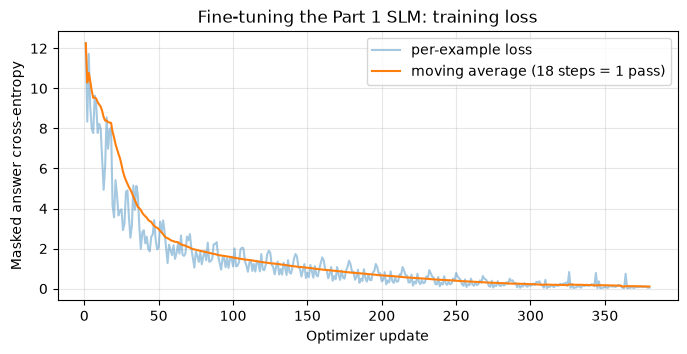

In [10]:
# CELL 10: Plot fine-tuning loss
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, len(loss_history) + 1), loss_history, alpha=0.4, label="per-example loss")
window = len(train_examples)
smoothed = [sum(loss_history[max(0, i - window + 1):i + 1]) / len(loss_history[max(0, i - window + 1):i + 1])
            for i in range(len(loss_history))]
plt.plot(range(1, len(smoothed) + 1), smoothed, label=f"moving average ({window} steps = 1 pass)")
plt.xlabel("Optimizer update")
plt.ylabel("Masked answer cross-entropy")
plt.title("Fine-tuning the Part 1 SLM: training loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
# CELL 11: Responses AFTER fine-tuning (same cues, same generation settings)
after_rows = []
for row in before_rows:
    result = generate_slm(model, row["Cue"])
    after_rows.append({"Question": row["Question"], "Expected Author": row["Expected Author"],
                       "Before Fine-Tuning": row["Response Before Fine-Tuning"],
                       "After Fine-Tuning": result["response"],
                       "Correct Before": row["Correct Before"],
                       "Correct After": first_line_correct(row["Question"], result["response"])})
after_df = pd.DataFrame(after_rows)
held_out_after = generate_slm(model, held_out["prompt"])["response"]
display(after_df)
print("Correct author on first line:", int(after_df["Correct Before"].sum()), "of 5 before ->",
      int(after_df["Correct After"].sum()), "of 5 after.")
print(f"\nHeld-out probe (never trained): {held_out['title']} by {held_out['author']}")
print("Before:", repr(held_out_before))
print("After: ", repr(held_out_after))
print("Held-out correct after:", first_line_correct("Held-out", held_out_after))

,Question,Expected Author,Before Fine-Tuning,After Fine-Tuning,Correct Before,Correct After
0,Q1,S.A. Cosby,stely offers courses in informatics.\nstudents...,s.a. cosby.\nthessron.\nstran.\nmattilli.\nang...,False,True
1,Q2,Susan Choi,utseful next token.\nork.\ninference uses prev...,susan choi.\nsmalli.\ndjansksarenn.\nmatttili....,False,True
2,Q3,Laila Lalami,weith language models.\nartificial intelligenc...,laila lalami.\nmallli.\nanguagelo.\natlail man...,False,True
3,Q4,Peyton Corinne,s deviews.\ntraining changes the weights of a ...,peyton corinne.\nstran.\nmattti nkaran.\nmattt...,False,True
4,Q5,Allegra Goodman,the ts use attention mechanisms.\nneural netwo...,allegra goodman.\nmattttivan.\nmatttivan.\nmat...,False,True


Correct author on first line: 0 of 5 before -> 5 of 5 after.

Held-out probe (never trained): North Sun by Ethan Rutherford
Before: 'leacontext token.\ntransformers use attention mechanisms.\nneural networks learn'
After:  'sine caserrrrik.\ninnon.\npy miode\nsk in.\nstran.\nmatti n.\ntran.\nmatthews.\ntran.\nm'
Held-out correct after: False


In [12]:
# CELL 12: Fine-tuning metrics
metrics_df = pd.DataFrame([
    ("SLM Architecture", f"Model #3: embedding {config['embedding_dim']}, {config['num_heads']} heads, "
                         f"{config['num_layers']} layer, feed-forward {config['feedforward_dim']}, "
                         f"context {config['context_length']}, vocab {len(chars)}"),
    ("Starting Checkpoint", CHECKPOINT_PATH.name + " (Part 1 selected model)"),
    ("Number of Fine-Tuning Examples", len(train_examples)),
    ("Learning Rate", LEARNING_RATE),
    ("Fine-Tuning Steps", f"{TRAINING_STEPS} ({TRAINING_STEPS / len(train_examples):.0f} passes, 1 example/step)"),
    ("Initial Fine-Tuning Loss", round(initial_ft_loss, 4)),
    ("Final Fine-Tuning Loss", round(final_ft_loss, 4)),
    ("Fine-Tuning Time", f"{fine_tuning_time:.2f} s"),
    ("Were Weights Updated?", f"{weights_updated} ({total_changed:,} / {total_elements:,} values)"),
    ("Original-Corpus Loss (before -> after)", f"{initial_corpus_loss:.4f} -> {final_corpus_loss:.4f}"),
], columns=["Metric", "Result"])
display(metrics_df)

,Metric,Result
0,SLM Architecture,"Model #3: embedding 48, 4 heads, 1 layer, feed..."
1,Starting Checkpoint,tiny_transformer.pt (Part 1 selected model)
2,Number of Fine-Tuning Examples,18
3,Learning Rate,0.001
4,Fine-Tuning Steps,"380 (21 passes, 1 example/step)"
5,Initial Fine-Tuning Loss,9.5682
6,Final Fine-Tuning Loss,0.0584
7,Fine-Tuning Time,0.27 s
8,Were Weights Updated?,"True (32,523 / 32,523 values)"
9,Original-Corpus Loss (before -> after),0.1330 -> 1.6230


## Step 3.3 Results

The cue and generation settings are the same as in Step 3.2. Only the weights differ. In the responses, `<br>` marks a generated newline. "Correct" means the first generated line is exactly the normalized author.

| Question | Before Fine-Tuning | After Fine-Tuning | Correct (Before → After) |
|---|---|---|---|
| **Q1** — Who wrote *King Of Ashes*? (S.A. Cosby) | stely offers courses in informatics.<br>students experiment with language models.<br>a | **s.a. cosby.**<br>thessron.<br>stran.<br>mattilli.<br>anguagell mieg.<br>skskared.<br>tran.<br>matttiva | No → **Yes** |
| **Q2** — Who wrote *Flashlight*? (Susan Choi) | utseful next token.<br>ork.<br>inference uses previously learned parameters.<br>the univ | **susan choi.**<br>smalli.<br>djansksarenn.<br>matttili.<br>an.<br>mati nksus.<br>atn<br>matttive rosar. | No → **Yes** |
| **Q3** — Who wrote *The Dream Hotel*? (Laila Lalami) | weith language models.<br>artificial intelligence can generate text.<br>the model pre | **laila lalami.**<br>mallli.<br>anguagelo.<br>atlail man.<br>mattivan.<br>matttivan.<br>matttivan.<br>ma | No → **Yes** |
| **Q4** — Who wrote *Unloved*? (Peyton Corinne) | s deviews.<br>training changes the weights of a neural network.<br>inference uses prev | **peyton corinne.**<br>stran.<br>mattti nkaran.<br>matttti lalli  man.<br>imatttilli.<br>anguagell | No → **Yes** |
| **Q5** — Who wrote *Isola*? (Allegra Goodman) | the ts use attention mechanisms.<br>neural networks learn from training data.<br>machi | **allegra goodman.**<br>mattttivan.<br>matttivan.<br>matttivativan.<br>matttivan.<br>matttivan.<br>ma | No → **Yes** |
| *Held-out probe:* `north sun by` (Ethan Rutherford, **not trained**) | leacontext token.<br>transformers use attention mechanisms.<br>neural networks learn | sine caserrrrik.<br>innon.<br>py miode<br>sk in.<br>stran.<br>matti n.<br>tran.<br>matthews.<br>tran.<br>m | No → No |

| Metric | Result |
|---|---|
| SLM Architecture | Model #3: embedding 48, 4 heads, 1 layer, feed-forward 192, context 32, 27-character vocabulary (32,523 parameters) |
| Starting Checkpoint | `tiny_transformer.pt`, the Part 1 selected model. Before-FT outputs match the Part 2 baseline exactly |
| Number of Fine-Tuning Examples | 18 (`<title> by <author>.\n`, loss on the author part only) |
| Learning Rate | 0.001 (AdamW) |
| Fine-Tuning Steps | 380 (1 example per step, about 21 passes) |
| Initial Fine-Tuning Loss | 9.5682 |
| Final Fine-Tuning Loss | 0.0584 |
| Fine-Tuning Time | 0.27 s (CPU, 2 threads) |
| Were Weights Updated? | Yes: 18/18 tensors and 32,523/32,523 values changed (mean absolute change per tensor 0.006–0.023) |
| Original-Corpus Loss (forgetting check) | 0.1330 → 1.6230 |

## Step 3.4: Analysis

1. **Did the SLM's responses change after fine-tuning?** Yes, all five did. Before fine-tuning, every cue was continued with sentences from the Part 1 course corpus. After fine-tuning, every response starts with an author name and a period, followed by repeated name-like fragments such as `mattivan.` and `stran.` instead of corpus sentences.

2. **Did fine-tuning improve factual accuracy?** Yes, for facts it was trained on: the first line contained the exact correct author for 5 of 5 questions, compared with 0 of 5 before. It did not generalize. The held-out book *North Sun*, which was never trained, produced the invented name `sine caserrrrik` rather than Ethan Rutherford. The gain is memorization of the 18 training facts.

3. **Did training loss decrease?** Yes. The masked answer loss fell from 9.5682 to 0.0584. Loss on a fixed sample of the original training corpus rose from 0.1330 to 1.6230. With only 18 short examples and no replay of the original data, the model overwrote much of what it had learned in Part 1 (catastrophic forgetting).

4. **Were the model's weights updated?** Yes. A full comparison against the checkpoint snapshot shows that all 18 parameter tensors and all 32,523 values changed. In Part 2, RAG left every weight identical to the checkpoint.

5. **Can a fine-tuned SLM still generate incorrect or unsupported information?** Yes. It invented an author for the held-out book, and every answer continues with fabricated name fragments that blend pieces of training authors (for example `matthews`, `lalli`). In Part 4, the fine-tuned model also produced wrong names when it was given a prompt format it had not been trained on.

# Part 4: Comparing Baseline, RAG, and Fine-Tuning

All three conditions start from the same `tiny_transformer.pt` checkpoint (Model #3) and use the same five questions, compact cues, temperature, seed, and generation length:

- **A. Baseline:** the original checkpoint with the cue only (Step 3.2 above).
- **B. RAG:** the original checkpoint with the **Top-1** retrieved prompt from Part 2. Top-1 was the only setting that kept the complete author name. The exact prompts are reproduced here and asserted to give the recorded Part 2 responses.
- **C. Fine-tuned:** the weights after Step 3.3, with the cue only and no retrieval.

An extra column, **C + RAG**, gives the fine-tuned model the same Top-1 RAG prompt. It provides evidence for the question of whether the two approaches can be combined.

In [13]:
# CELL 13: Three-condition comparison
# Top-1 prompts and responses recorded in assignment_P1-A7_RAG.ipynb.
RECORDED_RAG_TOP1 = {
    "Q1": [
        "s.a. cosby\nking of ashes by",
        "stems.\nlanguage models predict the next token.\ntransformers use attention mechan"
    ],
    "Q2": [
        "susan choi\nflashlight by",
        "uts th ton programming.\nstudents develop artificial intelligence systems.\nlangu"
    ],
    "Q3": [
        "laila lalami\nthe dream hotel by",
        "utses use models and views.\ntraining changes the weights of a neural network.\ni"
    ],
    "Q4": [
        "peyton corinne\nunloved by",
        "s learned parameters.\nthe university offers courses in informatics.\nstudents exp"
    ],
    "Q5": [
        "allegra goodman\nisola by",
        "the ts use nexperiment with language models.\nartificial intelligence can generat"
    ]
}

original_model = TinyTransformerLM(vocab_size=len(chars), **config).to(DEVICE)
original_model.load_state_dict(saved["model_state"], strict=True)
original_model.eval()
assert all(torch.equal(checkpoint_weights[n], t) for n, t in original_model.state_dict().items())

comparison_rows = []
for row in after_rows:
    qid = row["Question"]
    rag_prompt, recorded_rag_response = RECORDED_RAG_TOP1[qid]
    rag_response = generate_slm(original_model, rag_prompt)["response"]
    assert rag_response == recorded_rag_response, qid
    ft_rag_response = generate_slm(model, rag_prompt)["response"]
    comparison_rows.append({
        "Question": qid, "Expected Author": row["Expected Author"],
        "A. Baseline": row["Before Fine-Tuning"],
        "B. SLM + RAG (Top-1)": rag_response,
        "C. Fine-Tuned": row["After Fine-Tuning"],
        "C + RAG": ft_rag_response,
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

score_df = pd.DataFrame({
    "Condition": ["A. Baseline", "B. SLM + RAG (Top-1)", "C. Fine-Tuned", "C + RAG"],
    "Correct Author (first line)": [
        sum(first_line_correct(r["Question"], r[col]) for r in comparison_rows)
        for col in ["A. Baseline", "B. SLM + RAG (Top-1)", "C. Fine-Tuned", "C + RAG"]],
    "Weights Updated": [False, False, True, True],
})
display(score_df)
print("RAG responses reproduce Part 2 exactly; original weights unchanged.")

,Question,Expected Author,A. Baseline,B. SLM + RAG (Top-1),C. Fine-Tuned,C + RAG
0,Q1,S.A. Cosby,stely offers courses in informatics.\nstudents...,stems.\nlanguage models predict the next token...,s.a. cosby.\nthessron.\nstran.\nmattilli.\nang...,ss cors karettttokemr.\nstran.\nmatttivan.\nma...
1,Q2,Susan Choi,utseful next token.\nork.\ninference uses prev...,uts th ton programming.\nstudents develop arti...,susan choi.\nsmalli.\ndjansksarenn.\nmatttili....,srosench.\nsharansfroksor.\ntran.\nmatttive ro...
2,Q3,Laila Lalami,weith language models.\nartificial intelligenc...,utses use models and views.\ntraining changes ...,laila lalami.\nmallli.\nanguagelo.\natlail man...,miode ksusell.\nanguagom.\nsksul.\naneton.\npy...
3,Q4,Peyton Corinne,s deviews.\ntraining changes the weights of a ...,s learned parameters.\nthe university offers c...,peyton corinne.\nstran.\nmattti nkaran.\nmattt...,alon.\nine run hor.\nsmalli.\nang\nmati.\nsksk...
4,Q5,Allegra Goodman,the ts use attention mechanisms.\nneural netwo...,the ts use nexperiment with language models.\n...,allegra goodman.\nmattttivan.\nmatttivan.\nmat...,sres shelain kared.\ntran.\nmatttilli.\nanguag...


,Condition,Correct Author (first line),Weights Updated
0,A. Baseline,0,False
1,B. SLM + RAG (Top-1),0,False
2,C. Fine-Tuned,5,True
3,C + RAG,0,True


RAG responses reproduce Part 2 exactly; original weights unchanged.


## Step 4.1: Three-Condition Comparison

All three conditions start from the same checkpoint and use temperature 0.7, seed 42, and 80 new characters. `<br>` marks a generated newline. The RAG prompts are the Part 2 Top-1 prompts, for example `"s.a. cosby\nking of ashes by"`.

| Question | A. Baseline SLM | B. SLM + RAG (Top-1) | C. Fine-Tuned SLM | C + RAG (extra) |
|---|---|---|---|---|
| **Q1** *King Of Ashes* (S.A. Cosby) | stely offers courses in informatics.<br>students experiment with language models.<br>a | stems.<br>language models predict the next token.<br>transformers use attention mechan | **s.a. cosby.**<br>thessron.<br>stran.<br>mattilli.<br>anguagell mieg.<br>skskared.<br>tran.<br>matttiva | ss cors karettttokemr.<br>stran.<br>matttivan.<br>matttive ros y omioken.<br>lan.<br>matttie n |
| **Q2** *Flashlight* (Susan Choi) | utseful next token.<br>ork.<br>inference uses previously learned parameters.<br>the univ | uts th ton programming.<br>students develop artificial intelligence systems.<br>langu | **susan choi.**<br>smalli.<br>djansksarenn.<br>matttili.<br>an.<br>mati nksus.<br>atn<br>matttive rosar. | srosench.<br>sharansfroksor.<br>tran.<br>matttive rosar.<br>tran.<br>matthewsor.<br>tran.<br>mattti |
| **Q3** *The Dream Hotel* (Laila Lalami) | weith language models.<br>artificial intelligence can generate text.<br>the model pre | utses use models and views.<br>training changes the weights of a neural network.<br>i | **laila lalami.**<br>mallli.<br>anguagelo.<br>atlail man.<br>mattivan.<br>matttivan.<br>matttivan.<br>ma | miode ksusell.<br>anguagom.<br>sksul.<br>aneton.<br>py mioksnovor.<br>stran.<br>mattilli.<br>anguage |
| **Q4** *Unloved* (Peyton Corinne) | s deviews.<br>training changes the weights of a neural network.<br>inference uses prev | s learned parameters.<br>the university offers courses in informatics.<br>students exp | **peyton corinne.**<br>stran.<br>mattti nkaran.<br>matttti lalli  man.<br>imatttilli.<br>anguagell | alon.<br>ine run hor.<br>smalli.<br>ang<br>mati.<br>skskararan.<br>matttthewsorksor.<br>tran.<br>mattti |
| **Q5** *Isola* (Allegra Goodman) | the ts use attention mechanisms.<br>neural networks learn from training data.<br>machi | the ts use nexperiment with language models.<br>artificial intelligence can generat | **allegra goodman.**<br>mattttivan.<br>matttivan.<br>matttivativan.<br>matttivan.<br>matttivan.<br>ma | sres shelain kared.<br>tran.<br>matttilli.<br>anguagom mrtwan.<br>man<br>mattti lan.<br>mattilli. |
| **Correct author (first line)** | **0 / 5** | **0 / 5** | **5 / 5** | **0 / 5** |

| Criterion | A. Baseline | B. SLM + RAG | C. Fine-Tuned |
|---|---|---|---|
| **Factual accuracy** | 0/5. No author named. | 0/5. The correct author was in the prompt for every question, but no response repeated it. | 5/5 on the first line for trained books; 0/1 on the held-out book. |
| **Relevance** | Low. Continues Part 1 course sentences ("the university offers courses..."). | Low. Same kind of corpus continuation; the retrieved evidence only shifted which sentence came out. | High for the first line (the requested author); low afterward. |
| **Response consistency** | Deterministic for a fixed seed; fluent corpus sentences every time. | Deterministic, and reproduced Part 2 exactly; still fluent corpus sentences. | Consistent format (`author.` then fragments) for all five; rest of output degenerates into repeated fragments. |
| **Unsupported / invented information** | No invented authors; off-topic corpus text. | No invented authors; ignores supplied evidence. | Invents name-like fragments after every answer, invents an author for the unseen book, and has lost much of the original corpus (loss 0.133 → 1.623). |

## Step 4.2: Final Analysis

1. **Which condition produced the most accurate responses?** The fine-tuned SLM (Condition C). It named the correct author on the first line for 5 of 5 questions; the baseline and RAG each scored 0 of 5. Its accuracy covers only the books it memorized: the held-out book got an invented author.

2. **Which approach required updating model weights?** Fine-tuning. All 32,523 parameters changed. The baseline and RAG runs were asserted to leave every weight identical to the checkpoint.

3. **Which approach would be easier to maintain when information changes?** RAG. Changing a fact means editing a knowledge-base JSON record. With fine-tuning, every change requires retraining, re-checking old facts, and guarding against forgetting; here, 380 steps on 18 facts raised the original-corpus loss more than tenfold. With this SLM, though, RAG was easy to maintain but not effective: our model was never trained to copy information from its context.

4. **Which approach would you recommend for a startup with frequently changing policies?** RAG, paired with a generator that is able to read retrieved text: a larger pretrained model, or an SLM fine-tuned once on the evidence-then-question format. The policies themselves stay in the knowledge base. Fine-tuning facts directly would bake in policies that go stale, and our results show it can also erase earlier knowledge and invent answers for anything it was not trained on.

5. **Could RAG and fine-tuning be combined in the same language model?** Yes, but the fine-tuning has to teach the model to use retrieved context. Our naive combination (C + RAG) scored 0 of 5, below fine-tuning alone. The fine-tuned model had only seen `<title> by <author>` sequences, so the RAG prompt `<author>\n<title> by` was an unfamiliar format, and it produced wrong names. A working combination would fine-tune on examples formatted like the RAG prompts (retrieved evidence followed by the question and answer), so the weights learn the skill of reading context while the facts stay in the knowledge base.